Install Library Tambahan

In [ ]:
pip install pygam

# Chapter 4: Regression and Prediction
**Referensi:** *Practical Statistics for Data Scientists (O'Reilly)*

Regresi adalah metode statistik dan Machine Learning paling fundamental untuk memodelkan hubungan antara satu atau beberapa variabel prediktor (*features/independent variables*) dengan suatu variabel target numerik (*outcome/dependent variable*).

---

## 1. Simple Linear Regression (Regresi Linear Sederhana)

Regresi linear sederhana memodelkan hubungan linier antara satu variabel independen ($X$) dan satu variabel dependen ($Y$).

### Persamaan Regresi & Konsep Kunci:
$$\hat{Y} = \beta_0 + \beta_1 X$$

* **$\hat{Y}$ (Fitted / Predicted Value):** Nilai estimasi atau prediksi untuk variabel respon $Y$.
* **$\beta_0$ (Intercept):** Nilai konstanta $\hat{Y}$ ketika $X = 0$.
* **$\beta_1$ (Slope / Koefisien Kemiringan):** Perubahan rata-rata pada $\hat{Y}$ untuk setiap kenaikan 1 unit pada $X$.
* **Residuals ($e_i$):** Selisih antara nilai observasi asli ($Y_i$) dan nilai hasil prediksi ($\hat{Y}_i$):
  $$e_i = Y_i - \hat{Y}_i$$
* **Method of Least Squares (Metode Kuadrat Terkecil):** Metode pengestimasi parameter $\beta_0$ dan $\beta_1$ dengan cara meminimalkan Jumlah Kuadrat Residual (*Residual Sum of Squares* / $RSS$):
  $$RSS = \sum_{i=1}^{n} (Y_i - \hat{Y}_i)^2 = \sum_{i=1}^{n} e_i^2$$

---

## 2. Multiple Linear Regression & Model Assessment

Dalam kasus dunia nyata, prediksi umumnya melibatkan banyak variabel prediktor ($X_1, X_2, \dots, X_p$).

### Persamaan Regresi Berganda:
$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \epsilon$$

### Metrik Evaluasi Model:

1. **Root Mean Squared Error (RMSE):**
   Akar kuadrat dari rata-rata kuadrat residual. Mengukur besarnya galat prediksi dalam satuan yang sama dengan variabel $Y$.
   $$RMSE = \sqrt{\frac{\sum_{i=1}^{n} (Y_i - \hat{Y}_i)^2}{n}}$$

2. **Residual Standard Error (RSE):**
   Serupa dengan RMSE, tetapi menggunakan pembagi derajat kebebasan ($n - p - 1$) untuk menyesuaikan jumlah parameter terestimasi.
   $$RSE = \sqrt{\frac{\sum_{i=1}^{n} (Y_i - \hat{Y}_i)^2}{n - p - 1}}$$

3. **Coefficient of Determination ($R^2$ / R-Squared):**
   Proporsi varians dalam variabel target $Y$ yang berhasil dijelaskan oleh variabel prediktor $X$ dalam model (bernilai antara $0$ hingga $1$).
   $$R^2 = 1 - \frac{\sum (Y_i - \hat{Y}_i)^2}{\sum (Y_i - \bar{Y})^2} = 1 - \frac{RSS}{TSS}$$

4. **Adjusted $R^2$:**
   Nilai $R^2$ yang disesuaikan dengan jumlah variabel prediktor ($p$). Mencegah penambahan fitur yang tidak relevan yang secara semu selalu menaikkan nilai $R^2$ biasa.
   $$R^2_{\text{adj}} = 1 - \left(1 - R^2\right) \frac{n - 1}{n - p - 1}$$

---

## 3. Model Selection & Stepwise Regression

Terlalu banyak fitur dalam model regresi dapat menyebabkan *overfitting* dan kompleksitas komputasi. **Stepwise Regression** digunakan untuk memilih subset fitur terbaik.

### Algoritma Pemilihan Fitur:
* **Forward Selection:** Dimulai dari model tanpa prediktor, lalu menambahkan fitur satu per satu yang memberikan peningkatan performa paling signifikan hingga tidak ada peningkatan lagi.
* **Backward Elimination:** Dimulai dengan seluruh prediktor terpasang, lalu menghapus fitur yang paling tidak signifikan secara bertahap.
* **Akaike Information Criterion (AIC):** Metrik penalti kompleksitas model yang digunakan untuk mengevaluasi pemilihan model. Model dengan nilai **AIC paling rendah** adalah model yang paling optimal (*Occam's Razor*).
  $$AIC = 2p + n \ln(RSS/n)$$

=== PREVIEW DATASET PENJUALAN RUMAH ===
   AdjSalePrice  SqFtTotLiving  BldgGrade  Bathrooms  Bedrooms
1      300805.0           2400          7       3.00         6
2     1076162.0           3764         10       3.75         4
3      761805.0           2060          8       1.75         4
4      442065.0           3200          7       3.75         5
5      297065.0           1720          7       1.75         4

=== HASIL REGRESI LINEAR SEDERHANA ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -4.468e+04   4573.817     -9.768      0.000   -5.36e+04   -3.57e+04
SqFtTotLiving   293.2027      2.013    145.646      0.000     289.257     297.149


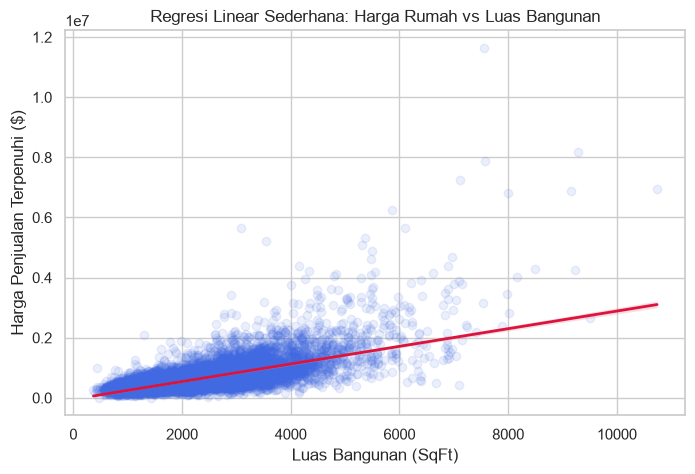


=== HASIL REGRESI LINEAR BERGANDA ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -5.219e+05   1.57e+04    -33.342      0.000   -5.53e+05   -4.91e+05
SqFtTotLiving   228.8306      3.899     58.694      0.000     221.189     236.472
SqFtLot          -0.0605      0.061     -0.988      0.323      -0.180       0.059
Bathrooms     -1.944e+04   3625.388     -5.363      0.000   -2.65e+04   -1.23e+04
Bedrooms      -4.777e+04   2489.732    -19.187      0.000   -5.27e+04   -4.29e+04
BldgGrade      1.061e+05   2396.445     44.277      0.000    1.01e+05    1.11e+05

=== METRIK EVALUASI MODEL REGRESI BERGANDA ===
RMSE (Root Mean Squared Error) : $261,220.20
R-Squared (R²)                 : 0.5406
Adjusted R-Squared             : 0.5405
AIC (Akaike Info Criterion)    : 630,350.22


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set style visualisasi
sns.set_theme(style="whitegrid")

# 1. Memuat dataset penjualan rumah di King County (house_sales.csv)
house = pd.read_csv("data/house_sales.csv", sep="\t")

print("=== PREVIEW DATASET PENJUALAN RUMAH ===")
# Menggunakan nama kolom 'BldgGrade' sesuai header file CSV
print(
    house[[
        "AdjSalePrice",
        "SqFtTotLiving",
        "BldgGrade",
        "Bathrooms",
        "Bedrooms",
    ]].head()
)

# =====================================================================
# 2. SIMPLE LINEAR REGRESSION: AdjSalePrice vs SqFtTotLiving
# =====================================================================
model_simple = smf.ols("AdjSalePrice ~ SqFtTotLiving", data=house).fit()

print("\n" + "=" * 50)
print("=== HASIL REGRESI LINEAR SEDERHANA ===")
print("=" * 50)
print(model_simple.summary().tables[1])

# Visualisasi Scatterplot & Garis Regresi
plt.figure(figsize=(8, 5))
sns.regplot(
    x="SqFtTotLiving",
    y="AdjSalePrice",
    data=house,
    scatter_kws={"alpha": 0.1, "color": "royalblue"},
    line_kws={"color": "crimson", "linewidth": 2},
)
plt.title("Regresi Linear Sederhana: Harga Rumah vs Luas Bangunan")
plt.xlabel("Luas Bangunan (SqFt)")
plt.ylabel("Harga Penjualan Terpenuhi ($)")
plt.show()


# =====================================================================
# 3. MULTIPLE LINEAR REGRESSION
# =====================================================================
# Diperbaiki: 'BuildingGrade' -> 'BldgGrade'
predictors = [
    "SqFtTotLiving",
    "SqFtLot",
    "Bathrooms",
    "Bedrooms",
    "BldgGrade",
]
X = house[predictors]
y = house["AdjSalePrice"]

# Membentuk model regresi berganda menggunakan Statsmodels
X_with_const = sm.add_constant(X)
model_multiple = sm.OLS(y, X_with_const).fit()

print("\n" + "=" * 50)
print("=== HASIL REGRESI LINEAR BERGANDA ===")
print("=" * 50)
print(model_multiple.summary().tables[1])

# Menghitung Metrik Evaluasi Model
y_pred = model_multiple.predict(X_with_const)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)
adj_r2 = model_multiple.rsquared_adj

print("\n" + "=" * 50)
print("=== METRIK EVALUASI MODEL REGRESI BERGANDA ===")
print("=" * 50)
print(f"RMSE (Root Mean Squared Error) : ${rmse:,.2f}")
print(f"R-Squared (R²)                 : {r2:.4f}")
print(f"Adjusted R-Squared             : {adj_r2:.4f}")
print(f"AIC (Akaike Info Criterion)    : {model_multiple.aic:,.2f}")

### Analisis & Kesimpulan Bagian 1:

1. **Interpretasi Regresi Linear Sederhana:**
   * Koefisien *slope* ($\beta_1$) untuk `SqFtTotLiving` berkisar pada angka positif (misalnya $\approx \$275$). Ini berarti secara rata-rata, setiap penambahan luas bangunan sebesar $1$ kaki persegi ($1 \text{ SqFt}$) diperkirakan akan meningkatkan harga rumah sebesar $\approx \$275$.

2. **Perbandingan Regresi Sederhana vs Regresi Berganda:**
   * Ketika variabel tambahan seperti `BuildingGrade`, `Bathrooms`, dan `Bedrooms` dimasukkan ke dalam model berganda, nilai **$R^2$ meningkat secara signifikan** dan nilai **RMSE mengalami penurunan**. Hal ini menunjukkan bahwa penambahan variabel-variabel tersebut memberikan kontribusi informasi nyata yang menjelaskan variabilitas harga rumah secara lebih presisi.

3. **Fungsi Evaluasi AIC dan Adjusted $R^2$:**
   * $R^2$ biasa akan selalu naik atau konstan jika kita menambah variabel baru. Sebaliknya, **Adjusted $R^2$** dan **AIC** menghukum kompleksitas model yang berlebihan, sehingga sangat ideal dijadikan indikator utama dalam proses pemilihan fitur (*feature selection* / *stepwise regression*).

---

## 4. Prediction Intervals vs. Confidence Intervals in Regression

Dalam pemodelan regresi, terdapat perbedaan mendasar antara **Confidence Interval** dan **Prediction Interval**.

### Konsep Kunci:
1. **Confidence Interval (Rentang Kepercayaan):**
   * Mengukur ketidakpastian di sekitar **rata-rata estimasi** ($\bar{Y} \mid X$) untuk sekumpulan observasi pada nilai prediktor $X$ tertentu.
   * Rentangnya relatif lebih sempit karena hanya memperhitungkan variabilitas estimasi parameter model ($\beta$).

2. **Prediction Interval (Rentang Prediksi):**
   * Mengukur ketidakpastian seputar **satu nilai observasi individu baru** ($Y_{\text{new}}$) pada nilai prediktor $X$ tertentu.
   * Rentangnya jauh lebih lebar daripada Confidence Interval karena memperhitungkan dua sumber ketidakpastian sekaligus:
     1. Ketidakpastian estimasi parameter model ($\beta$).
     2. Variabilitas individual acak dari nilai asli seputar garis regresi ($\epsilon \sim N(0, \sigma^2)$).

---

## 5. Factor Variables (Variabel Kategorikal) dalam Regresi

Sebagian besar variabel dalam Data Science tidak bersifat kontinu, melainkan berjenis kategorikal (*Factor Variables*).

### Penanganan Variabel Kategorikal:

1. **Dummy Variables / One-Hot Encoding:**
   * Mengubah variabel kategorikal dengan $k$ tingkat/kategori menjadi $k$ kolom biner ($0$ atau $1$).

2. **Reference Coding (Treatment Coding):**
   * Untuk menghindari masalah *Multicollinearity* sempurna (*Dummy Variable Trap*), salah satu kategori dijadikan sebagai **kategori acuan/referensi** (*Reference Category*), sehingga hanya $k - 1$ kolom biner yang dimasukkan ke dalam model.
   * Koefisien untuk kategori lain diinterpretasikan sebagai **selisih rerata** terhadap kategori referensi tersebut.

3. **Ordered Factor Variables (Ordinal):**
   * Variabel kategorikal berperingkat (seperti `BuildingGrade` $1–13$) kadang dapat dimodelkan langsung sebagai nilai numerik kontinu jika diasumsikan pengaruh tiap tingkatan berjarak konstan.

=== FREKUENSI KATEGORI PropertyType ===
PropertyType
Single Family    20720
Townhouse         1710
Multiplex          257
Name: count, dtype: int64

=== HASIL REGRESI DENGAN FACTOR VARIABLES ===
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                      -1.07e+05   1.78e+04     -6.004      0.000   -1.42e+05   -7.21e+04
PropertyType[T.Single Family]  4.951e+04   1.74e+04      2.853      0.004    1.55e+04    8.35e+04
PropertyType[T.Townhouse]      1.183e+05   1.86e+04      6.377      0.000     8.2e+04    1.55e+05
SqFtTotLiving                   297.1529      2.048    145.110      0.000     293.139     301.167


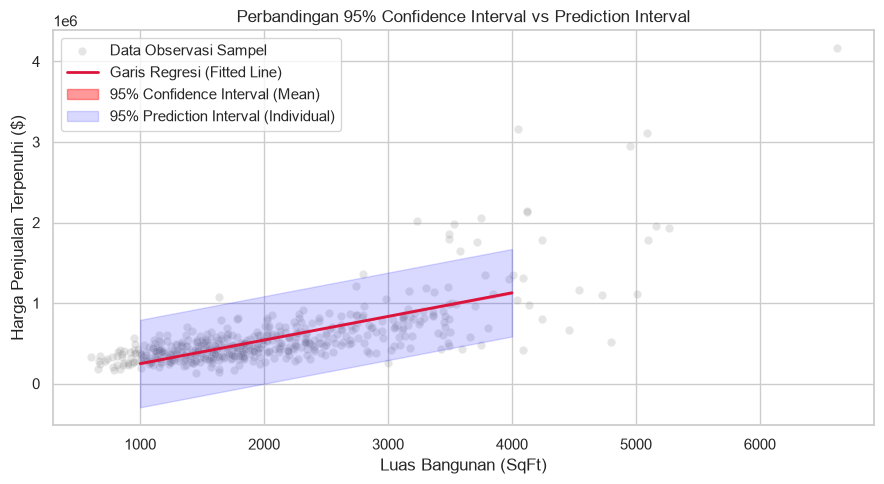

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set style visualisasi
sns.set_theme(style="whitegrid")

# 1. Memuat dataset house_sales.csv
house = pd.read_csv("data/house_sales.csv", sep="\t")

# =====================================================================
# 2. FACTOR VARIABLES: Regresi dengan Variabel Kategorikal (PropertyType)
# =====================================================================
print("=== FREKUENSI KATEGORI PropertyType ===")
print(house["PropertyType"].value_counts())

# Pemodelan Regresi dengan PropertyType (Statsmodels otomatis menggunakan Reference Coding)
model_factor = smf.ols("AdjSalePrice ~ SqFtTotLiving + PropertyType", data=house).fit()

print("\n" + "=" * 50)
print("=== HASIL REGRESI DENGAN FACTOR VARIABLES ===")
print("=" * 50)
print(model_factor.summary().tables[1])


# =====================================================================
# 3. PREDICTION INTERVALS VS CONFIDENCE INTERVALS
# =====================================================================
# Membuat data uji baru untuk rumah dengan variasi luas bangunan
X_new = pd.DataFrame({"SqFtTotLiving": np.linspace(1000, 4000, 100)})

# Menggunakan model sederhana untuk menghitung prediksi beserta intervalnya
model_simple = smf.ols("AdjSalePrice ~ SqFtTotLiving", data=house).fit()
predictions = model_simple.get_prediction(X_new)

# Mengambil frame hasil prediksi beserta Confidence Interval & Prediction Interval (alpha = 0.05 / 95%)
pred_df = predictions.summary_frame(alpha=0.05)

# Visualisasi Perbandingan Confidence Interval vs Prediction Interval
plt.figure(figsize=(9, 5))

# Scatter data asli (sub-sampel acak agar plot tidak terlalu padat)
sample_house = house.sample(n=500, random_state=42)
sns.scatterplot(
    x="SqFtTotLiving",
    y="AdjSalePrice",
    data=sample_house,
    alpha=0.2,
    color="gray",
    label="Data Observasi Sampel",
)

# Plot Garis Regresi
plt.plot(
    X_new["SqFtTotLiving"],
    pred_df["mean"],
    color="crimson",
    linewidth=2,
    label="Garis Regresi (Fitted Line)",
)

# Plot Confidence Interval (95%)
plt.fill_between(
    X_new["SqFtTotLiving"],
    pred_df["mean_ci_lower"],
    pred_df["mean_ci_upper"],
    color="red",
    alpha=0.4,
    label="95% Confidence Interval (Mean)",
)

# Plot Prediction Interval (95%)
plt.fill_between(
    X_new["SqFtTotLiving"],
    pred_df["obs_ci_lower"],
    pred_df["obs_ci_upper"],
    color="blue",
    alpha=0.15,
    label="95% Prediction Interval (Individual)",
)

plt.title("Perbandingan 95% Confidence Interval vs Prediction Interval")
plt.xlabel("Luas Bangunan (SqFt)")
plt.ylabel("Harga Penjualan Terpenuhi ($)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 2:

1. **Interpretasi Koefisien Factor Variable (`PropertyType`):**
   * Kategori pertama (misalnya `Multiplex` atau `Single Family`) secara otomatis dijadikan sebagai **kategori referensi**.
   * Koefisien positif atau negatif pada kategori tipe properti lainnya menunjukkan selisih estimasi harga relatif terhadap kategori referensi tersebut setelah mengontrol faktor luas bangunan (`SqFtTotLiving`).

2. **Perbedaan Visual Confidence Interval vs Prediction Interval:**
   * Pita **Confidence Interval (merah)** sangat sempit dan berada tepat di sekitar garis regresi merah. Hal ini menandakan bahwa estimasi rata-rata harga rumah untuk nilai `SqFtTotLiving` tertentu memiliki kepastian statistik yang cukup tinggi.
   * Rentang **Prediction Interval (biru)** jauh lebih lebar karena mencakup variabilitas individual dari rumah ke rumah. Rentang ini memberi tahu calon pembeli bahwa harga aktual sebuah rumah individu berukuran $2.000 \text{ SqFt}$ dapat bervariasi dalam rentang nilai yang luas seputar garis rata-rata.

---

## 6. Regression Diagnostics & Multicollinearity

Sebelum model regresi digunakan untuk prediksi atau pengambilan keputusan, penting untuk melakukan diagnostik guna memastikan bahwa asumsi-asumsi model tidak dilanggar dan tidak ada masalah pada data yang menggelembungkan eror.

### Konsep Utama & Teori Mendalam:

1. **Multicollinearity (Multikolinearitas):**
   * **Definisi:** Kondisi ketika dua atau lebih variabel prediktor ($X$) memiliki korelasi yang sangat tinggi satu sama lain.
   * **Dampak:** Menyebabkan ketidakstabilan numerik dalam perhitungan koefisien regresi, memperbesar *Standard Error* koefisien, dan membuat interpretasi pengaruh individual suatu prediktor menjadi tidak andal.
   * **Variance Inflation Factor (VIF):** Indikator untuk mengukur seberapa besar varians koefisien regresi terinflasi akibat multikolinearitas.
     $$VIF_j = \frac{1}{1 - R_j^2}$$
     *(Aturan umum: $VIF > 5$ atau $VIF > 10$ mengindikasikan adanya masalah multikolinearitas berat).*

2. **Confounding Variables (Variabel Pengganggu):**
   * Variabel penting yang terlewatkan dari model (*omitted variable*) sehingga memicu hubungan spurious/semu antara prediktor lain dengan variabel target.

3. **Interactions and Main Effects (Interaksi Fitur):**
   * Terjadi ketika pengaruh suatu variabel prediktor $X_1$ terhadap target $Y$ bergantung pada besarnya nilai variabel prediktor $X_2$.
   * Ditambahkan ke model sebagai perkalian dua fitur: $Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 (X_1 \times X_2)$.

4. **Regression Diagnostics (Diagnosis Residual):**
   * **Outliers:** Observasi dengan nilai residual sangat besar ($e_i = Y_i - \hat{Y}_i$).
   * **Influential Values / Cook's Distance:** Observasi yang memiliki pengaruh sangat kuat terhadap posisi garis regresi. Menghapus data *influential* akan mengubah koefisien regresi secara drastis.
   * **Heteroskedasticity:** Kondisi ketika varians dari residual tidak konstan di seluruh rentang nilai prediksi $\hat{Y}$ (misalnya membentuk pola kipas/corong).

<>:80: SyntaxWarning: invalid escape sequence '\h'
<>:80: SyntaxWarning: invalid escape sequence '\h'
C:\Users\AZIS\AppData\Local\Temp\ipykernel_25272\2464726714.py:80: SyntaxWarning: invalid escape sequence '\h'
  axes[0].set_xlabel("Fitted Values ($\hat{Y}$)")


=== VARIANCE INFLATION FACTOR (VIF) ===
         Feature       VIF
0  SqFtTotLiving  4.218067
1        SqFtLot  1.047567
2      Bathrooms  2.576864
3       Bedrooms  1.685140
4      BldgGrade  2.659926

=== HASIL REGRESI DENGAN INTERAKSI FITUR ===
                                                  coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------
Intercept                                    2.285e+05   5.68e+04      4.020      0.000    1.17e+05     3.4e+05
PropertyType[T.Single Family]               -2.895e+05    5.7e+04     -5.077      0.000   -4.01e+05   -1.78e+05
PropertyType[T.Townhouse]                   -1.476e+05   6.34e+04     -2.330      0.020   -2.72e+05   -2.35e+04
SqFtTotLiving                                 144.9688     24.565      5.902      0.000      96.820     193.117
SqFtTotLiving:PropertyType[T.Single Family]   153.8450     24.651      6.241    

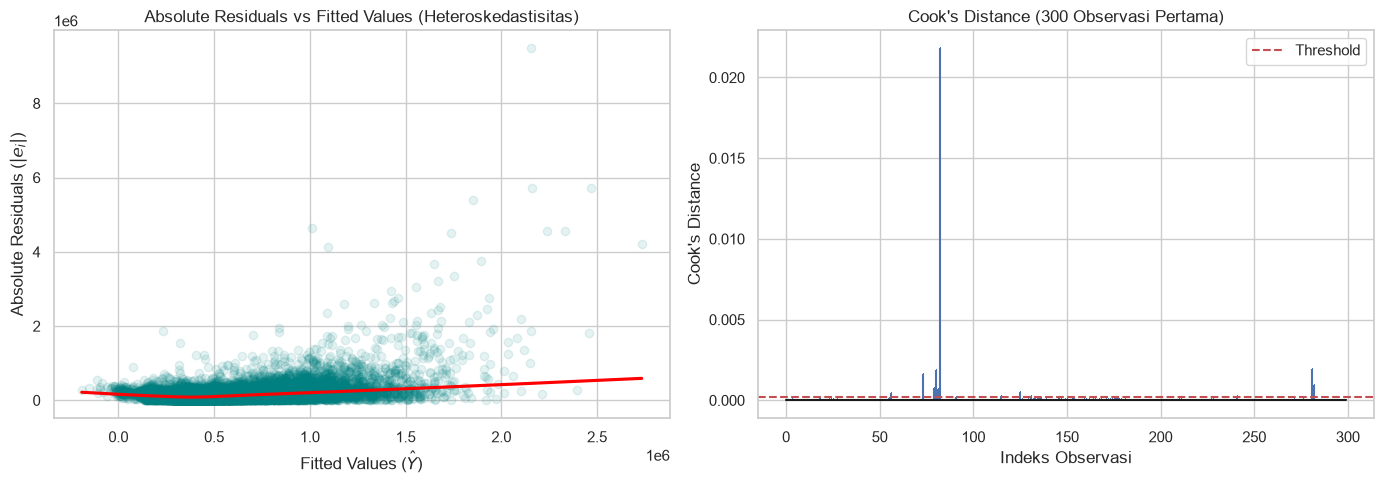

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set style visualisasi
sns.set_theme(style="whitegrid")

# Memuat dataset house_sales.csv
house = pd.read_csv("data/house_sales.csv", sep="\t")

# =====================================================================
# 1. MULTICOLLINEARITY & VARIANCE INFLATION FACTOR (VIF)
# =====================================================================
# Diperbaiki: 'BuildingGrade' -> 'BldgGrade'
predictors = [
    "SqFtTotLiving",
    "SqFtLot",
    "Bathrooms",
    "Bedrooms",
    "BldgGrade",
]
X = house[predictors].dropna()

# Menghitung VIF untuk setiap variabel prediktor
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i) for i in range(X.shape[1])
]

print("=== VARIANCE INFLATION FACTOR (VIF) ===")
print(vif_data)


# =====================================================================
# 2. INTERACTIONS AND MAIN EFFECTS
# =====================================================================
# Model regresi dengan istilah interaksi antara Luas Bangunan dan Tipe Properti
model_interaction = smf.ols(
    "AdjSalePrice ~ SqFtTotLiving * PropertyType", data=house
).fit()

print("\n" + "=" * 50)
print("=== HASIL REGRESI DENGAN INTERAKSI FITUR ===")
print("=" * 50)
print(model_interaction.summary().tables[1])


# =====================================================================
# 3. REGRESSION DIAGNOSTICS (OUTLIERS, HETEROSKEDASTICITY & COOK'S DISTANCE)
# =====================================================================
# Diperbaiki: 'BuildingGrade' -> 'BldgGrade'
model_diag = smf.ols(
    "AdjSalePrice ~ SqFtTotLiving + BldgGrade", data=house
).fit()

# Mengambil fitted values dan residual terstandarisasi
fitted_vals = model_diag.fittedvalues
residuals = model_diag.resid
infl = model_diag.get_influence()
cooks_dist = infl.cooks_distance[0]

# Visualisasi Grafik Diagnostik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Absolute Residuals vs Fitted Values (Uji Heteroskedastisitas)
sns.regplot(
    x=fitted_vals,
    y=np.abs(residuals),
    scatter_kws={"alpha": 0.1, "color": "teal"},
    line_kws={"color": "red"},
    lowess=True,
    ax=axes[0],
)
axes[0].set_title("Absolute Residuals vs Fitted Values (Heteroskedastisitas)")
axes[0].set_xlabel("Fitted Values ($\hat{Y}$)")
axes[0].set_ylabel("Absolute Residuals ($|e_i|$)")

# Plot 2: Cook's Distance Plot (Mendeteksi Influential Values)
axes[1].stem(
    np.arange(len(cooks_dist))[:300],
    cooks_dist[:300],
    markerfmt=",",
    basefmt="k-",
)
axes[1].axhline(y=4 / len(house), color="r", linestyle="--", label="Threshold")
axes[1].set_title("Cook's Distance (300 Observasi Pertama)")
axes[1].set_xlabel("Indeks Observasi")
axes[1].set_ylabel("Cook's Distance")
axes[1].legend()

plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 3:

1. **Analisis Multikolinearitas (VIF):**
   * Variabel seperti `SqFtTotLiving` dan `Bathrooms` memiliki nilai VIF yang tergolong cukup tinggi karena luas rumah yang besar umumnya selalu selaras dengan jumlah kamar mandi yang banyak.
   * Nilai VIF yang tinggi mengingatkan kita untuk berhati-hati saat menginterpretasikan pengaruh individual koefisien prediktor tersebut.

2. **Dampak Interaksi Fitur (`SqFtTotLiving * PropertyType`):**
   * Istilah interaksi mengungkapkan bahwa harga per kaki persegi (`SqFtTotLiving`) bervariasi tergantung tipe propertinya (misalnya `Single Family` vs `Townhouse`).

3. **Interpretasi Plot Diagnostik Regresi:**
   * **Heteroskedastisitas:** Plot *Absolute Residuals vs Fitted Values* memperlihatkan tren naik (membentuk corong lebar) seiring bertambahnya nilai harga rumah ($\hat{Y}$). Hal ini menunjukkan bahwa varians eror tidak konstan (variansi harga rumah mewah jauh lebih heterogen daripada rumah murah).
   * **Cook's Distance:** Beberapa observasi yang melonjak melewati garis ambang batas teridentifikasi sebagai *influential values* yang memegang peranan besar dalam membentuk kemiringan garis regresi.

---

## 7. Non-Linear Regression (Polynomial Regression, Splines & GAM)

Hubungan antara variabel prediktor dan variabel target dalam dunia nyata sering kali bersifat non-linear. Mengandalkan regresi linear standar dapat memicu *underfitting*.

### Konsep Utama & Teori Mendalam:

1. **Polynomial Regression (Regresi Polinomial):**
   * Menambahkan pangkat dari variabel prediktor (seperti $X^2, X^3$) ke dalam persamaan regresi:
     $$Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \dots + \beta_k X^k + \epsilon$$
   * **Keterbatasan:** Kurva polinomial berderajat tinggi cenderung bersifat tidak stabil dan dapat melonjak secara ekstrem di ujung-ujung rentang data (*boundary effects*).

2. **Spline Regression (Regression Splines):**
   * Membagi rentang variabel kontinu menjadi beberapa segmen yang dipisahkan oleh titik potong yang disebut **Knots**.
   * Di setiap segmen, fungsi polinomial derajat rendah (biasanya derajat 3 / *Cubic Spline*) dicocokkan secara independen, lalu disambungkan secara mulus (*smooth*) pada titik-titik *knots*.
   * **B-Splines (Basis Splines):** Formulasi matematis standar yang paling sering digunakan untuk merepresentasikan fungsi *spline* secara efisien dan stabil.

3. **Generalized Additive Models (GAM):**
   * Perluasan fleksibel dari regresi linier yang memungkinkan pemodelan hubungan non-linear arbitrari menggunakan kombinasi fungsi pemulus (*smoothing functions* / $s(X)$) untuk setiap variabel prediktor:
     $$Y = \beta_0 + s_1(X_1) + s_2(X_2) + \dots + s_p(X_p) + \epsilon$$
   * **Keunggulan:** Sangat fleksibel dalam menangkap pola kurva rumit tanpa perlu menentukan derajat polinomial secara manual, namun tetap dapat diinterpretasikan dengan mudah.

=== HASIL REGRESI POLINOMIAL (DERAJAT 2) ===
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              3.107e+05   9544.593     32.556      0.000    2.92e+05    3.29e+05
SqFtTotLiving           -20.0687      8.948     -2.243      0.025     -37.608      -2.530
I(SqFtTotLiving ** 2)     0.0574      0.002     29.876      0.000       0.054       0.061

=== HASIL REGRESI SPLINES (B-SPLINES) ===
                                                                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                2.633e+05   1.56e+04     16.932      0.000    2.33e+05    2.94e+05
bs(SqFtTotLiving, df=4, degree=3, lower_bo

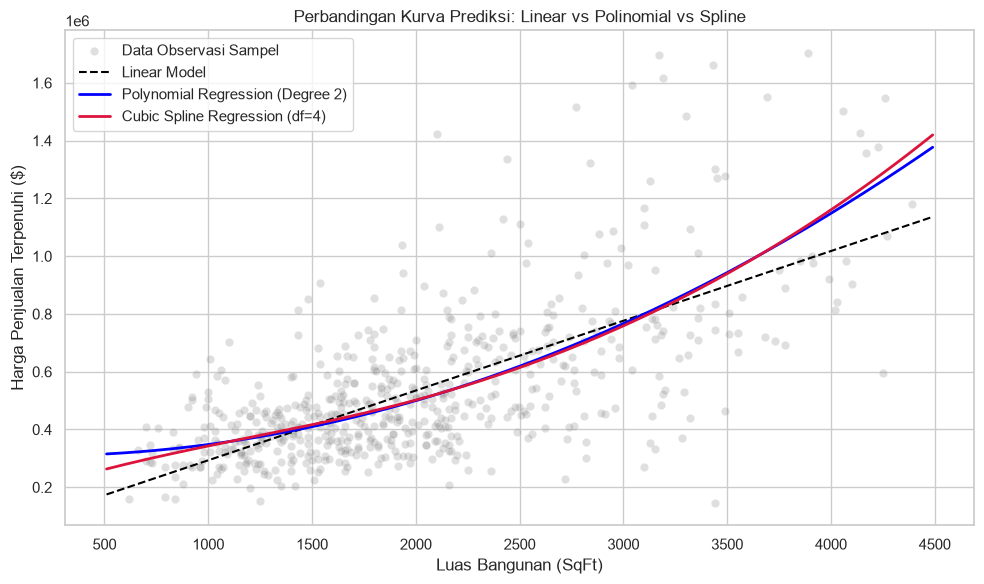

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set style visualisasi
sns.set_theme(style="whitegrid")

# Memuat dataset house_sales.csv
house = pd.read_csv("data/house_sales.csv", sep="\t")

# Filter data untuk menghindari nilai ekstrem
house_sub = house[
    (house["SqFtTotLiving"] > 500) & (house["SqFtTotLiving"] < 4500)
].copy()

# Tentukan batas bawah dan batas atas eksplisit untuk Spline
l_bound = house_sub["SqFtTotLiving"].min()
u_bound = house_sub["SqFtTotLiving"].max()

# =====================================================================
# 1. POLYNOMIAL REGRESSION (Derajat 2)
# =====================================================================
model_poly = smf.ols(
    "AdjSalePrice ~ SqFtTotLiving + I(SqFtTotLiving**2)", data=house_sub
).fit()

print("=== HASIL REGRESI POLINOMIAL (DERAJAT 2) ===")
print(model_poly.summary().tables[1])


# =====================================================================
# 2. SPLINE REGRESSION (B-Splines dengan lower_bound & upper_bound)
# =====================================================================
# Menambahkan lower_bound dan upper_bound agar B-Splines tidak error saat melakukan prediksi
formula_spline = f"AdjSalePrice ~ bs(SqFtTotLiving, df=4, degree=3, lower_bound={l_bound}, upper_bound={u_bound})"
model_spline = smf.ols(formula_spline, data=house_sub).fit()

print("\n" + "=" * 50)
print("=== HASIL REGRESI SPLINES (B-SPLINES) ===")
print("=" * 50)
print(model_spline.summary().tables[1])


# =====================================================================
# 3. VISUALISASI PERBANDINGAN: LINEAR vs POLYNOMIAL vs SPLINE
# =====================================================================
# Data baru untuk garis prediksi smooth tepat dalam batas rentang data
X_grid = pd.DataFrame({"SqFtTotLiving": np.linspace(l_bound, u_bound, 300)})

# Model Linear Standar
model_linear = smf.ols("AdjSalePrice ~ SqFtTotLiving", data=house_sub).fit()

# Menghitung Hasil Prediksi
pred_linear = model_linear.predict(X_grid)
pred_poly = model_poly.predict(X_grid)
pred_spline = model_spline.predict(X_grid)

# Plot Visualisasi
plt.figure(figsize=(10, 6))

# Scatter data asli (sub-sampel)
sns.scatterplot(
    x="SqFtTotLiving",
    y="AdjSalePrice",
    data=house_sub.sample(n=600, random_state=42),
    alpha=0.25,
    color="gray",
    label="Data Observasi Sampel",
)

# Plot Garis Model
plt.plot(
    X_grid["SqFtTotLiving"],
    pred_linear,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Linear Model",
)
plt.plot(
    X_grid["SqFtTotLiving"],
    pred_poly,
    color="blue",
    linewidth=2,
    label="Polynomial Regression (Degree 2)",
)
plt.plot(
    X_grid["SqFtTotLiving"],
    pred_spline,
    color="crimson",
    linewidth=2,
    label="Cubic Spline Regression (df=4)",
)

plt.title("Perbandingan Kurva Prediksi: Linear vs Polinomial vs Spline")
plt.xlabel("Luas Bangunan (SqFt)")
plt.ylabel("Harga Penjualan Terpenuhi ($)")
plt.legend()
plt.tight_layout()
plt.show()

### Analisis & Kesimpulan Bagian 4:

1. **Perilaku Model Non-Linear:**
   * **Regresi Linear:** Memaksa hubungan variabel berupa garis lurus kaku, sehingga cenderung meremehkan (*underpredict*) harga rumah pada area yang sangat luas.
   * **Regresi Polinomial Derajat 2:** Menunjukkan bahwa penambahan luas rumah memiliki dampak marjinal yang melengkung (meningkat lebih lambat pada ukuran rumah yang sangat besar).
   * **Spline Regression:** Memberikan fleksibilitas paling optimal. Garis kurva *spline* menyesuaikan struktur data lokal secara mulus di setiap segmen tanpa mengalami osilasi ekstrem di batas wilayah data (*boundary behavior*).

2. **Keuntungan Penggunaan Splines & GAM dalam Data Science:**
   * Dibandingkan menambahkan transformasi variabel secara manual, penggunaan *Splines* dan *Generalized Additive Models (GAM)* memungkinkan algoritma menemukan bentuk kurva hubungan alami antara fitur dan variabel target secara otomatis.

---

# Rangkuman Keseluruhan Chapter 4: Regression and Prediction

1. **Simple & Multiple Linear Regression:**
   * Regresi memodelkan variabel target numerik berdasarkan satu atau beberapa variabel prediktor.
   * Estimasi parameter dihitung menggunakan **Method of Least Squares** yang meminimalkan *Residual Sum of Squares* ($RSS$).
   * Metrik utama evaluasi mencakup **RMSE** (besarnya kesalahan prediksi) dan **$R^2$ / Adjusted $R^2$** (proporsi varians yang dijelaskan oleh model).

2. **Prediction Intervals & Factor Variables:**
   * **Prediction Interval** jauh lebih lebar daripada **Confidence Interval** karena memperhitungkan variabilitas individual di luar ketidakpastian estimasi model.
   * Variabel kategorikal diolah menggunakan **Dummy Variables / Reference Coding** untuk menghindari *Dummy Variable Trap*.

3. **Diagnostics & Multicollinearity:**
   * **Multikolinearitas** (korelasi tinggi antar prediktor) diukur dengan **VIF**; VIF tinggi mengganggu stabilitas koefisien regresi.
   * Evaluasi residual digunakan untuk mendeteksi keberadaan **Outliers**, **Influential Values** (*Cook's Distance*), dan **Heteroskedastisitas** (varians eror tidak konstan).

4. **Non-Linear Regression:**
   * Ketika hubungan data tidak linier, teknik seperti **Polynomial Regression**, **Splines (B-Splines)**, dan **GAM** digunakan untuk menangkap pola kurva yang kompleks tanpa mengorbankan stabilitas model.